# Grad-CAM: where does the model look?

For one nodule, Grad-CAM makes a heatmap the same size as the cube: high = this region pushed
the chosen rating's score up. Used here to look at the model's worst mistakes.

Reads:  runs/cls_no_fold/<run>/best.pt, config.json, <split>_preds.csv
        the patches on the external drive (plug in Expansion first)

It's a picture, not proof: show it as "where the model looked" on a few examples, never as a metric.

In [7]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "Model" else Path.cwd()
sys.path.insert(0, str(PROJECT / "Model"))                 # net.py
sys.path.insert(0, str(PROJECT / "Model" / "no_folds"))    # the no-folds Dataset
from net import NoduleNet3D
from dataset_patches_no_fold import NoduleDataset, CROP

RUNS_DIR = PROJECT / "runs" / "cls_no_fold"
RUNS = {"hard": "hard_seed1", "soft": "soft_seed1"}   # one model A and one model B, compared side by side
SPLIT = "val"       # look at val freely; only use "test" for a final figure, never to change the model

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("device", device)

device mps


## 1. Load the trained models

In [8]:
def load_model(run):
    cfg = json.loads((RUNS_DIR / run / "config.json").read_text())
    if cfg["crop"] != CROP:
        raise ValueError(f"{run} was trained on {cfg['crop']} mm crops but the Dataset cuts {CROP} mm")
    model = NoduleNet3D().to(device)
    model.load_state_dict(torch.load(RUNS_DIR / run / "best.pt", map_location=device))
    return model.eval()        # eval: dropout off, BatchNorm uses its saved averages

models = {kind: load_model(run) for kind, run in RUNS.items()}

## 2. Load the cubes and each model's predictions

The cubes are the same for hard and soft; only the target differs, so one Dataset is enough.
`err` = predicted rating − true (median) rating, so −2 means the model said 2 lower than the readers.

In [9]:
data = NoduleDataset(SPLIT, "hard")
df = data.df[["nodule_key", "ratings", "hard", "spread", "diameter_mm"]].copy()

P_COLS = [f"p{k}" for k in range(1, 6)]
for kind, run in RUNS.items():
    preds = pd.read_csv(RUNS_DIR / run / f"{SPLIT}_preds.csv").set_index("nodule_key")
    probs = preds.loc[df["nodule_key"], P_COLS].to_numpy()
    df[f"pred_{kind}"] = probs.argmax(1) + 1          # index 0..4 -> rating 1..5
    df[f"err_{kind}"] = df[f"pred_{kind}"] - df["hard"]

# check: the loaded model reproduces the saved predictions (catches a wrong run, crop or checkpoint)
for kind, model in models.items():
    preds = pd.read_csv(RUNS_DIR / RUNS[kind] / f"{SPLIT}_preds.csv").set_index("nodule_key")
    x = torch.stack([data[i][0] for i in range(5)]).to(device)
    with torch.no_grad():
        now = torch.softmax(model(x), 1).cpu().numpy()
    saved = preds.loc[df["nodule_key"][:5], P_COLS].to_numpy()
    print(f"{kind}: largest difference from the saved probabilities {np.abs(now - saved).max():.5f} (should be ~0)")

print(f"{len(df)} {SPLIT} nodules")
df.head()

hard: largest difference from the saved probabilities 0.00000 (should be ~0)
soft: largest difference from the saved probabilities 0.00000 (should be ~0)
290 val nodules


,nodule_key,ratings,hard,spread,diameter_mm,pred_hard,err_hard,pred_soft,err_soft
0,LIDC-IDRI-0006_920957_02,3;4;3;2,3,2,8.281250,3,0,3,0
1,LIDC-IDRI-0006_920957_03,3;3,3,0,6.250000,3,0,3,0
2,LIDC-IDRI-0012_457842_01,2;3;3;2,3,1,6.308598,3,0,3,0
3,LIDC-IDRI-0012_457842_02,4;3;5;2,4,3,11.875008,4,0,4,0
4,LIDC-IDRI-0012_457842_03,3;3;3;2,3,1,7.050786,3,0,3,0


## 3. Grad-CAM

1. Run the cube through the model, keeping the chosen layer's output (the activations: where each channel fires).
2. Backpropagate the score to that layer (the gradients: how much each channel matters for the score).
3. Weight per channel = its average gradient. Heatmap = weighted sum of the channels, negatives set to 0.
4. Stretch the heatmap up to the cube's size and scale it to 0..1.

The score is log P(rating in `classes`). With a 40 mm crop, `model.features[4]` (third block) is
10×10×10, so 4 mm per cell; `model.features[6]` (last block) is 5×5×5, so 8 mm per cell.

In [10]:
def grad_cam(model, x, layer, classes):
    """x: one cube (1, 1, CROP, CROP, CROP). classes: ratings to explain, e.g. [4, 5] for 'suspicious'."""
    store = {}
    def keep(module, inp, out):
        store["act"] = out
        out.register_hook(lambda g: store.update(grad=g))   # tensor hook: safe with ReLU(inplace=True)
    h = layer.register_forward_hook(keep)
    model.eval()
    out = model(x)
    idx = [c - 1 for c in classes]
    score = torch.logsumexp(out[0, idx], 0) - torch.logsumexp(out[0], 0)   # log P(those ratings)
    model.zero_grad()
    score.backward()
    h.remove()
    w = store["grad"].mean(dim=(2, 3, 4), keepdim=True)        # how much each channel mattered
    cam = F.relu((w * store["act"]).sum(1, keepdim=True)).detach().cpu()
    cam = F.interpolate(cam, size=x.shape[2:], mode="trilinear", align_corners=False)[0, 0]
    return (cam / (cam.max() + 1e-8)).numpy()

## 4. Plot one nodule

Rows: the three centre slices through the cube. Columns: the CT, then each model's heatmap on top.
By default each model's map explains **its own predicted rating** ("why did you say this?").
Pass `classes=[4, 5]` instead to ask both models the same question ("what looks suspicious to you?").

In [11]:
c = CROP // 2
VIEWS = {"axial": lambda v: v[c], "coronal": lambda v: v[:, c], "sagittal": lambda v: v[:, :, c]}

def show(i, classes=None, layer=4):
    row = df.iloc[i]
    x = data[i][0].unsqueeze(0).to(device)
    ct = x[0, 0].cpu().numpy()
    cams = {}
    for kind, model in models.items():
        cls = classes or [int(row[f"pred_{kind}"])]
        cams[kind] = (grad_cam(model, x, model.features[layer], cls), cls)

    fig, axes = plt.subplots(3, 1 + len(cams), figsize=(3 * (1 + len(cams)), 9))
    for r, (view, cut) in enumerate(VIEWS.items()):
        axes[r, 0].imshow(cut(ct), cmap="gray", vmin=-1, vmax=1)
        axes[r, 0].set_ylabel(view)
        for col, (kind, (cam, cls)) in enumerate(cams.items(), start=1):
            axes[r, col].imshow(cut(ct), cmap="gray", vmin=-1, vmax=1)
            axes[r, col].imshow(cut(cam), cmap="jet", alpha=0.4, vmin=0, vmax=1)
            if r == 0:
                axes[r, col].set_title(f"{kind}: predicted {row[f'pred_{kind}']}\nexplaining rating(s) {cls}")
    axes[0, 0].set_title("CT")
    for ax in axes.flat:
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"{row['nodule_key']}   readers {row['ratings']} -> true {row['hard']}   "
                 f"{row['diameter_mm']:.0f} mm", y=1.0)
    fig.tight_layout()
    plt.show()

## 5. The worst mistakes

Nodules where a model's rating is off by 2 or more. Look for a pattern: is the heat on the nodule,
or on a vessel, the chest wall, or the edge of the cube?

In [12]:
worst = df[(df["err_hard"].abs() >= 2) | (df["err_soft"].abs() >= 2)]
worst = worst.reindex(worst[["err_hard", "err_soft"]].abs().max(axis=1).sort_values(ascending=False).index)
print(f"{len(worst)} of {len(df)} nodules are off by 2 or more in at least one model")
worst

11 of 290 nodules are off by 2 or more in at least one model


,nodule_key,ratings,hard,spread,diameter_mm,pred_hard,err_hard,pred_soft,err_soft
45,LIDC-IDRI-0141_183786_02,2;3;4;4,4,2,11.837891,1,-3,1,-3
285,LIDC-IDRI-1002_740405_01,5;4;3;3,4,2,9.045410,1,-3,1,-3
26,LIDC-IDRI-0064_148666_01,3;4;3;2,3,2,27.734375,5,2,5,2
65,LIDC-IDRI-0181_295147_07,2;2,2,0,11.328125,4,2,4,2
94,LIDC-IDRI-0318_626096_01,1;1;3,1,2,8.658854,3,2,1,0
132,LIDC-IDRI-0484_714351_01,5;3;3;1,3,4,19.742188,4,1,5,2
155,LIDC-IDRI-0559_677129_02,1;1,1,0,5.195316,3,2,3,2
160,LIDC-IDRI-0594_417124_01,3;3,3,0,19.890625,5,2,3,0
169,LIDC-IDRI-0619_159586_02,5;5;5;5,5,0,25.473624,3,-2,5,0
180,LIDC-IDRI-0655_453512_05,2;3,3,1,5.835938,2,-1,1,-2


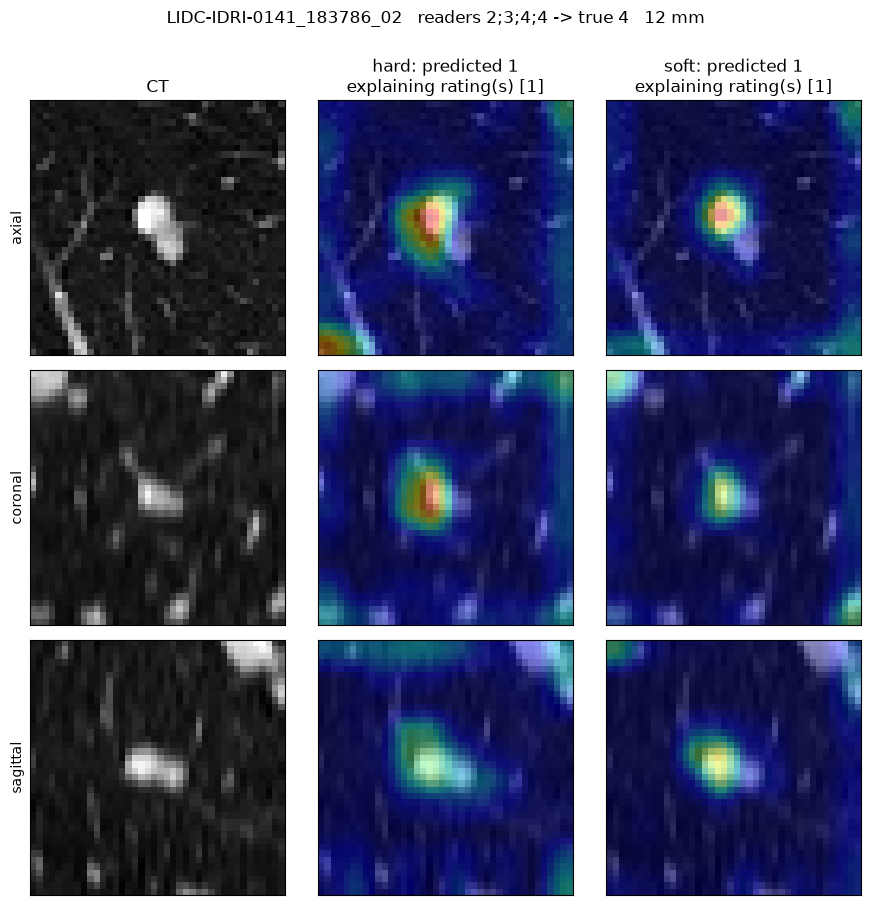

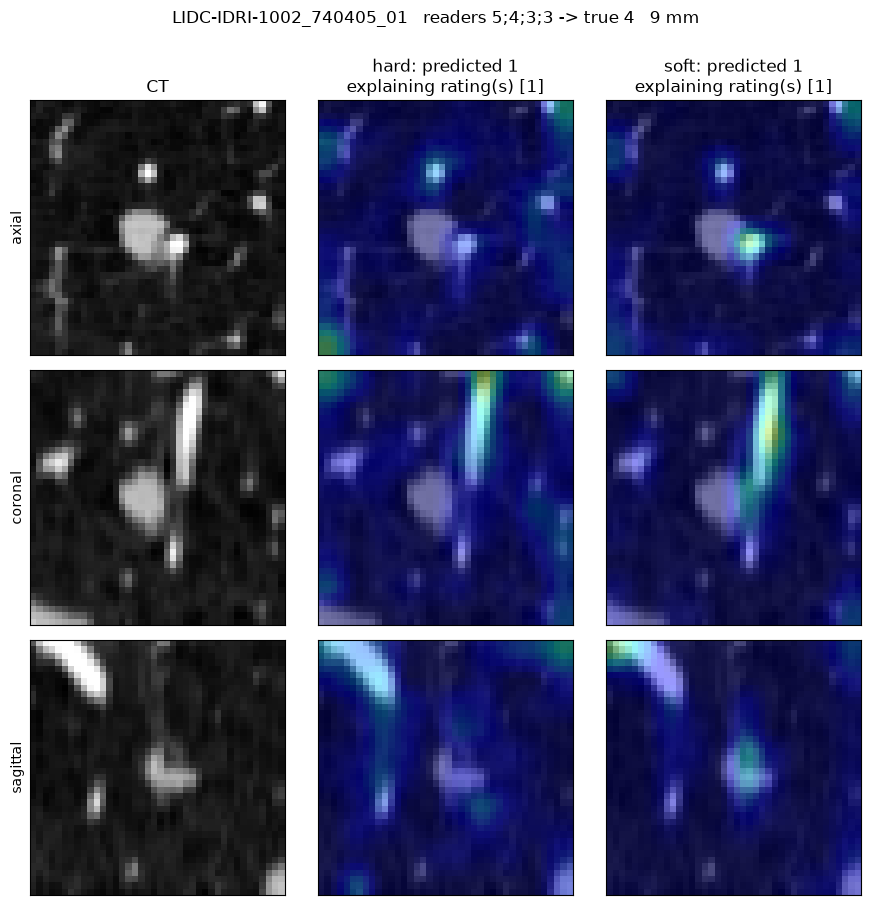

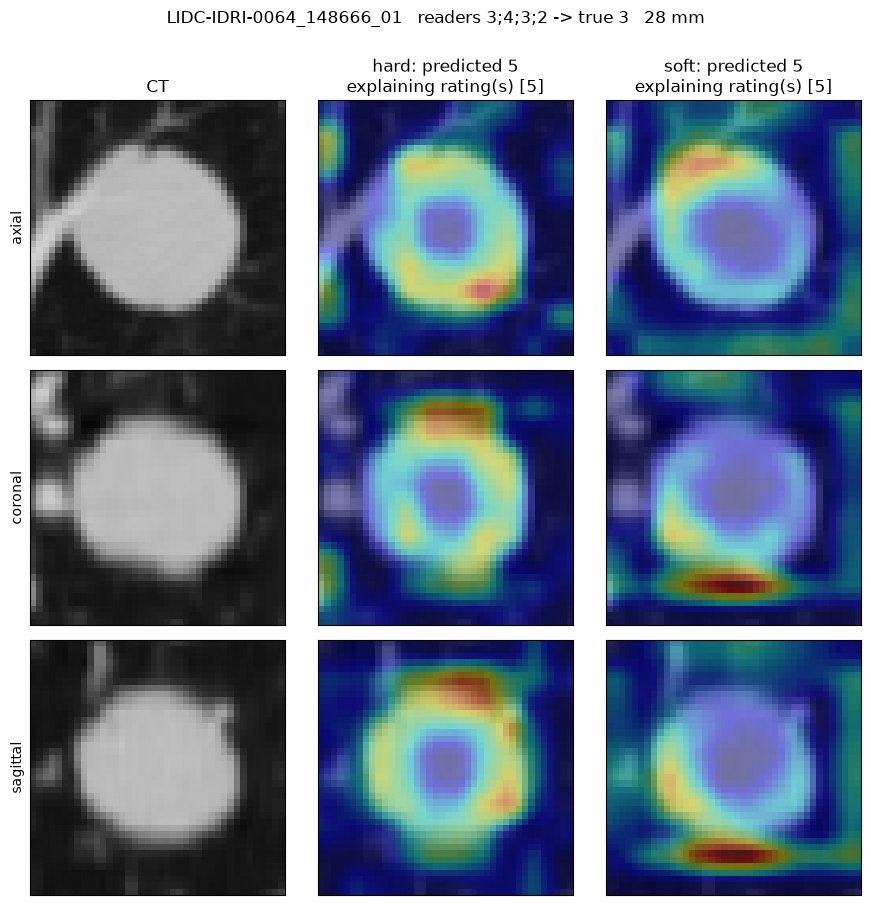

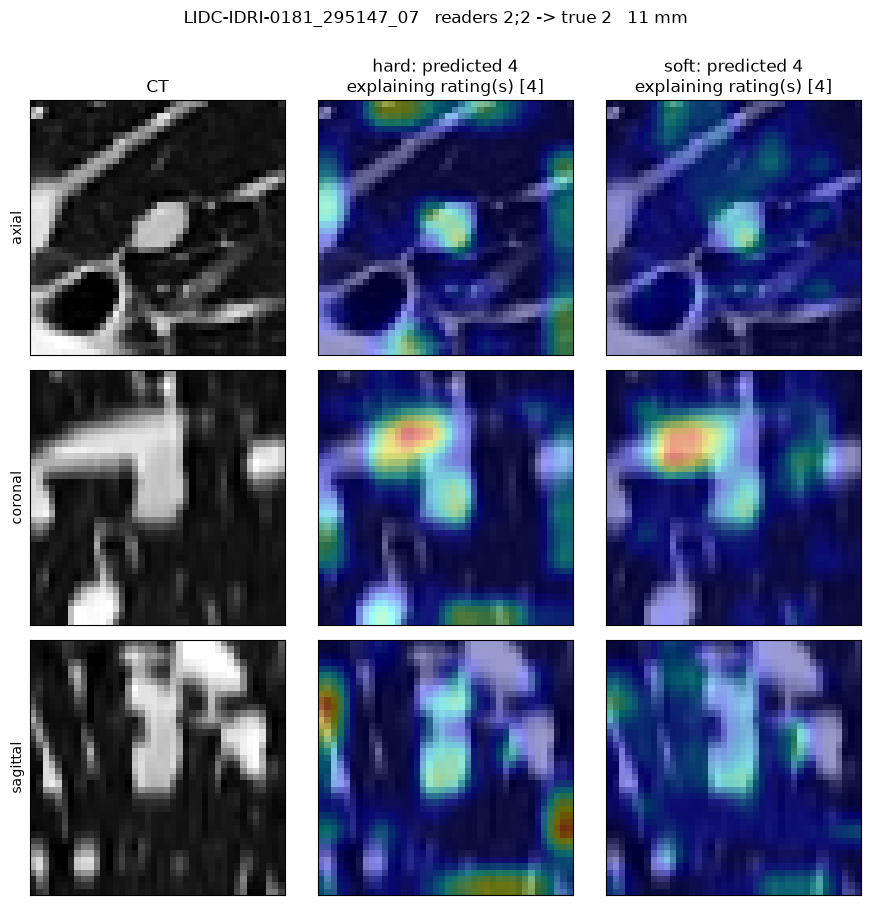

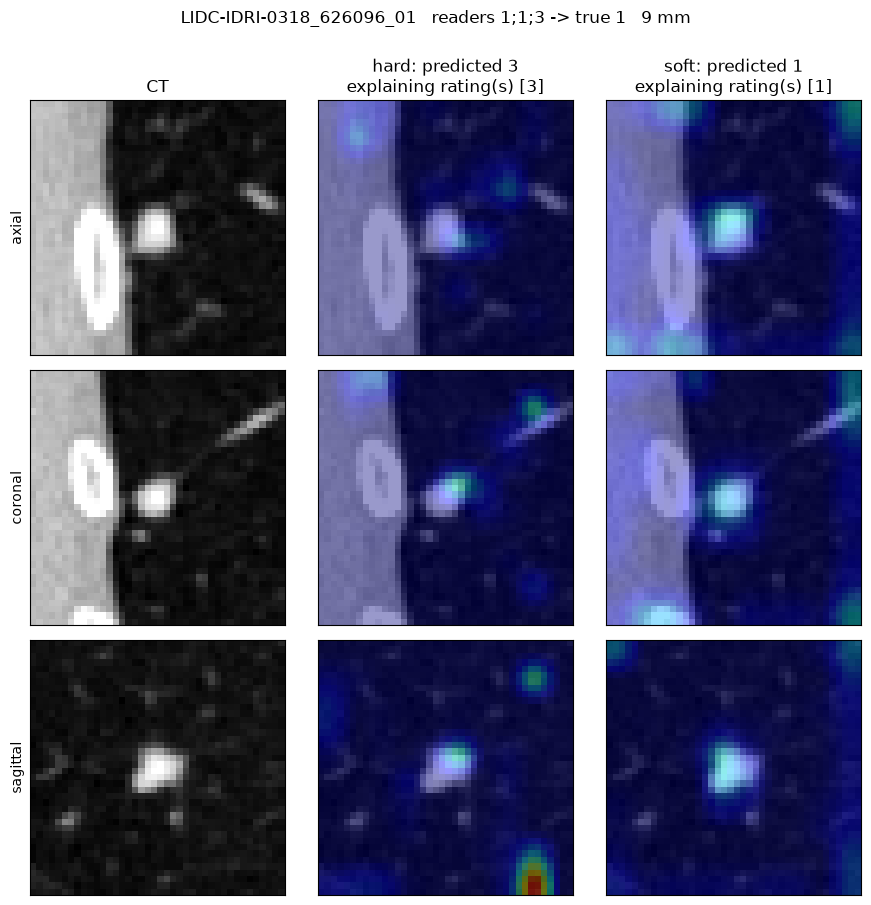

In [13]:
for i in worst.index[:5]:
    show(i)

## 6. For comparison: nodules both models got right

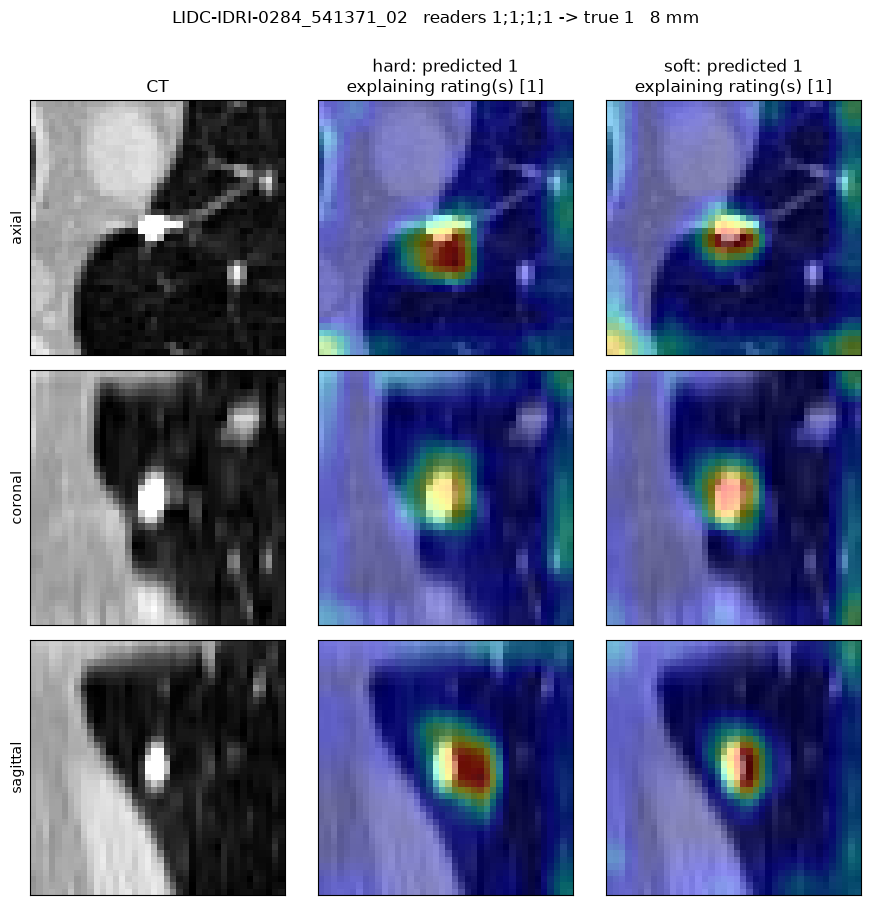

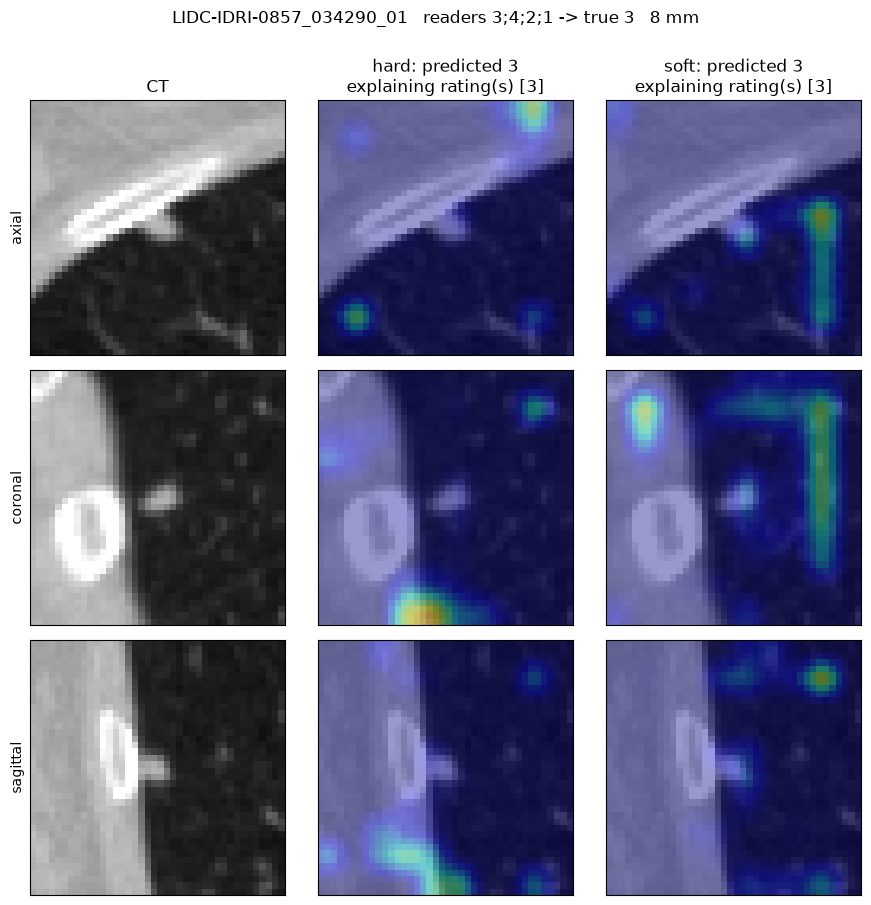

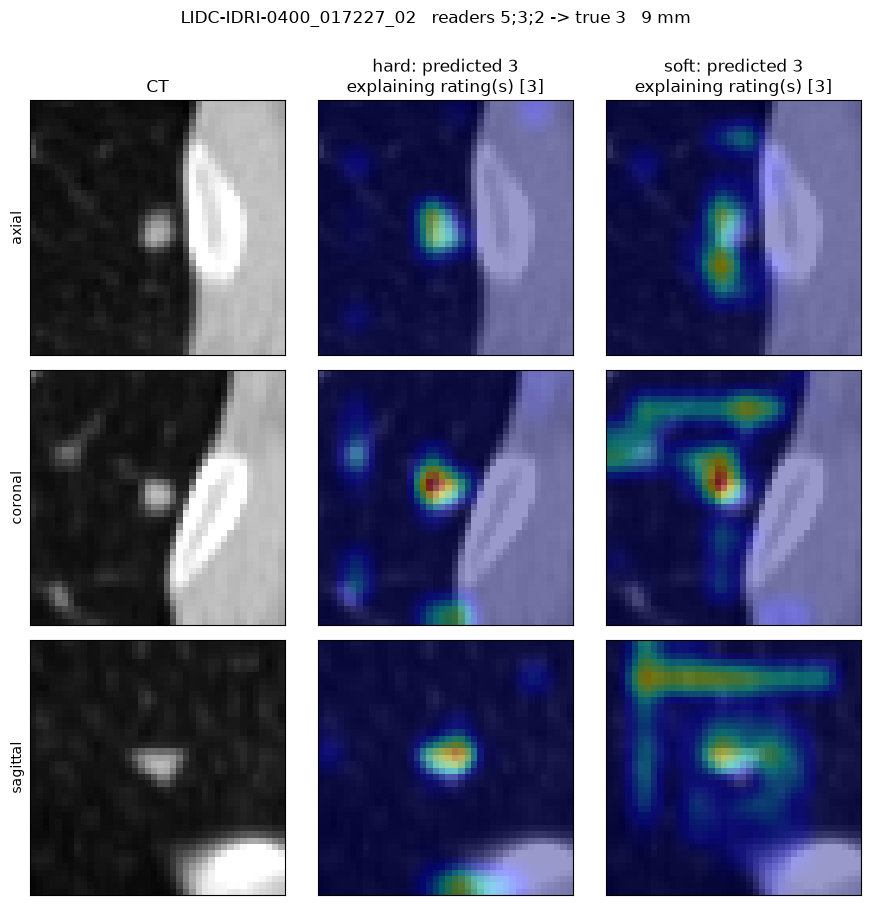

In [14]:
right = df[(df["err_hard"] == 0) & (df["err_soft"] == 0)]
for i in right.sample(3, random_state=0).index:
    show(i)

## 7. Hard vs soft where the readers disagreed most

`spread` = highest reader rating − lowest. Same question to both models: what looks suspicious?

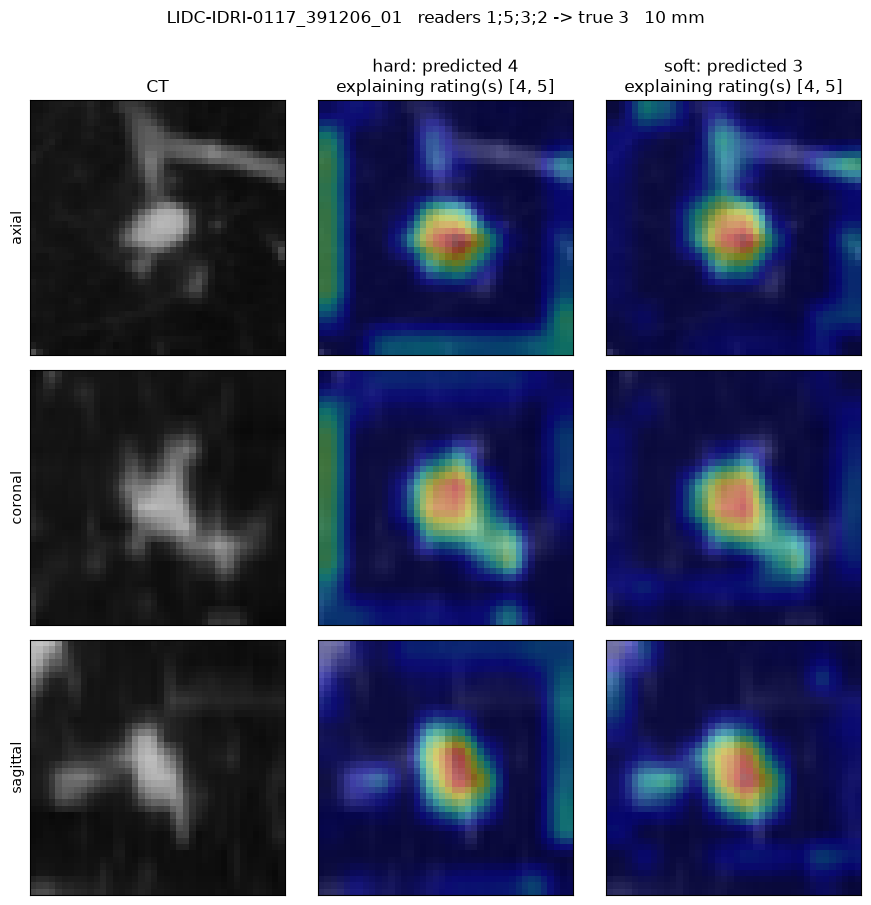

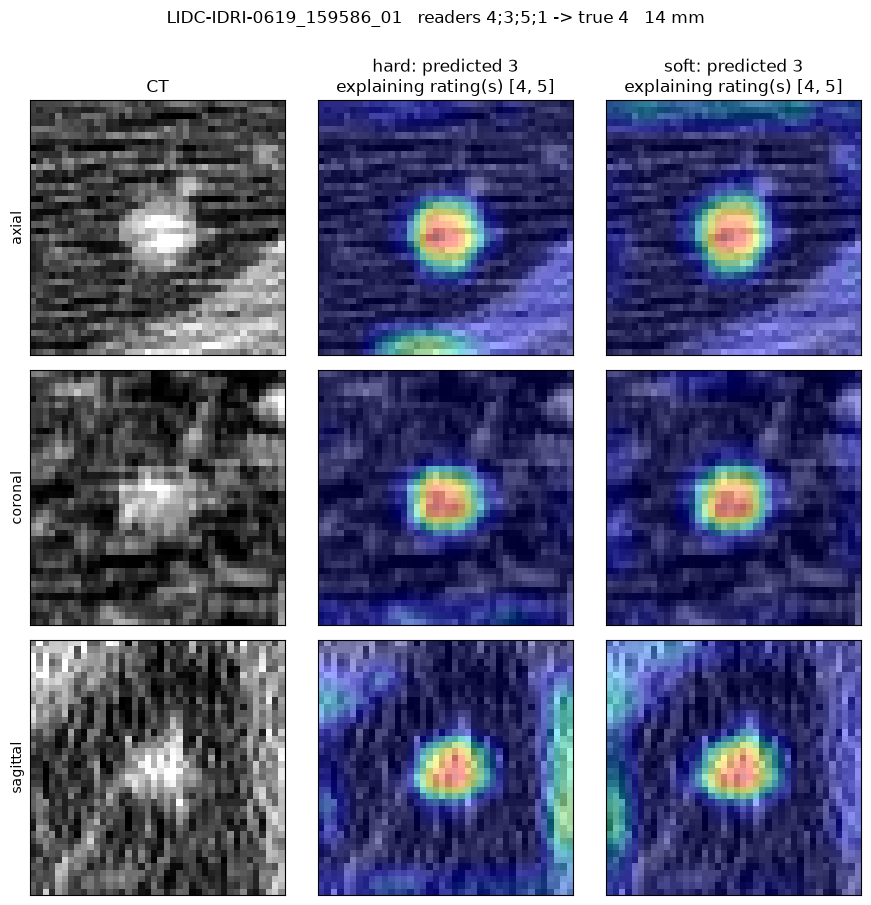

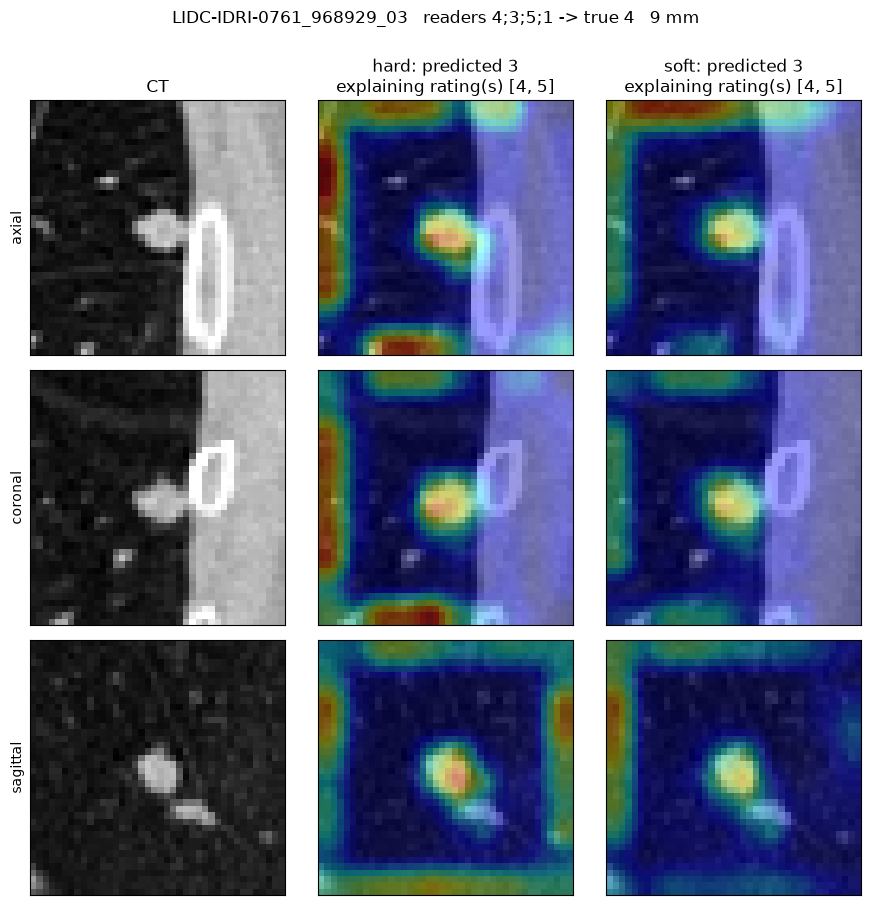

In [15]:
for i in df.sort_values("spread", ascending=False).index[:3]:
    show(i, classes=[4, 5])